# Εργασία 4 – Naive Bayes

Σε αυτή την εργασία προβλέπω αν ένα tweet αναφέρεται σε πραγματική φυσική καταστροφή (target 1) ή όχι (target 0). Αρχικά καθαρίζω τα κείμενα, μετά τα μετατρέπω σε TF-IDF χαρακτηριστικά και τέλος εκπαιδεύω Gaussian Naive Bayes.

# Import Libraries

In [1]:
from pathlib import Path
import re
import string
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

seed = 0

# Load Dataset

Το train.csv είναι από τον διαγωνισμό [Natural Language Processing with Disaster Tweets](https://www.kaggle.com/competitions/nlp-getting-started/data). Αν το αρχείο δεν υπάρχει στο Colab, κατεβαίνει αυτόματα από δημόσιο αντίγραφο του ίδιου dataset.

In [2]:
data_path = Path('train.csv')
data_url = 'https://raw.githubusercontent.com/juliuswiscmsba/NLP-Disaster-Tweets/main/train.csv'

if not data_path.exists():
    urllib.request.urlretrieve(data_url, data_path)

df = pd.read_csv(data_path)
print('Διαστάσεις:', df.shape)
df.head()

Διαστάσεις: (7613, 5)


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [3]:
df.isna().sum()

id             0
keyword       61
location    2533
text           0
target         0
dtype: int64

Το dataset έχει 7.613 tweets. Το id είναι απλό αναγνωριστικό, το keyword είναι η λέξη αναζήτησης, το location είναι η τοποθεσία, το text είναι το κείμενο και το target είναι η κλάση που θέλω να προβλέψω. Οι περισσότερες κενές τιμές βρίσκονται στο location και στο keyword.

# Train–Test Split 90–10%

In [4]:
train_df, test_df = train_test_split(
    df,
    test_size=0.10,
    random_state=seed,
    stratify=df['target'],
)

print('Train samples:', len(train_df))
print('Test samples:', len(test_df))

Train samples: 6851
Test samples: 762


## Κατανομή του target

Ελέγχω πόσα δείγματα από κάθε κλάση υπάρχουν στα train και test sets.

,Train,Test
target,,
0,3907,435
1,2944,327


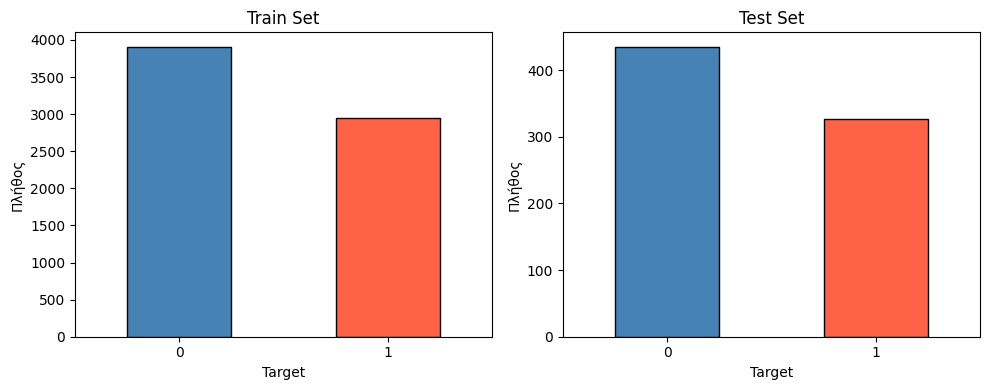

,Train %,Test %
target,,
0,57.0,57.1
1,43.0,42.9


In [5]:
train_counts = train_df['target'].value_counts().sort_index()
test_counts = test_df['target'].value_counts().sort_index()

counts = pd.DataFrame({'Train': train_counts, 'Test': test_counts})
display(counts)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
train_counts.plot(kind='bar', ax=axes[0], color=['steelblue', 'tomato'], edgecolor='black')
test_counts.plot(kind='bar', ax=axes[1], color=['steelblue', 'tomato'], edgecolor='black')

axes[0].set_title('Train Set')
axes[1].set_title('Test Set')
for ax in axes:
    ax.set_xlabel('Target')
    ax.set_ylabel('Πλήθος')
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

pd.DataFrame({
    'Train %': train_df['target'].value_counts(normalize=True).sort_index() * 100,
    'Test %': test_df['target'].value_counts(normalize=True).sort_index() * 100,
}).round(1)

**Ερώτηση: Είναι ισορροπημένο το dataset;**

**Απάντηση:** Όχι απόλυτα. Η κλάση 0 είναι περίπου 57% και η κλάση 1 περίπου 43%. Η διαφορά δεν είναι πολύ μεγάλη, άρα υπάρχει μικρή ανισορροπία. Με το stratify τα ίδια ποσοστά διατηρούνται και στα δύο sets.

# Text Preprocessing

Χρησιμοποίησα τις παρακάτω τεχνικές από το repository [text-preprocessing-techniques](https://github.com/Deffro/text-preprocessing-techniques):

| Τεχνική | Τι κάνει και γιατί τη χρησιμοποίησα |
|---|---|
| Remove Unicode | Αφαιρεί emoji και περίεργους χαρακτήρες που δεν βοηθούν την πρόβλεψη. |
| Replace URLs | Αντικαθιστά όλα τα links με τη λέξη url, γιατί η ακριβής διεύθυνση δεν έχει σημασία. |
| Replace User Mentions | Αντικαθιστά τα usernames με atUser, ώστε κάθε όνομα να μη γίνεται διαφορετική λέξη. |
| Remove Hashtag Symbol | Αφαιρεί μόνο το # αλλά κρατά τη λέξη, γιατί π.χ. το wildfire είναι χρήσιμη πληροφορία. |
| Remove Punctuation | Αφαιρεί σημεία στίξης και σύμβολα που δημιουργούν περιττό θόρυβο. |
| Lowercase | Μετατρέπει όλα τα γράμματα σε πεζά, ώστε Fire και fire να θεωρούνται ίδια λέξη. |

Δεν αφαίρεσα αριθμούς και stopwords, γιατί μπορεί να περιέχουν χρήσιμη πληροφορία για μια καταστροφή.

In [6]:
def removeUnicode(text):
    text = re.sub(r'(\\u[0-9A-Fa-f]+)', '', text)
    return re.sub(r'[^\x00-\x7f]', '', text)


def replaceURL(text):
    text = re.sub(r'((www\.[^\s]+)|(https?://[^\s]+))', 'url', text)
    text = re.sub(r'#([^\s]+)', r'\1', text)
    return text


def replaceAtUser(text):
    return re.sub(r'@[^\s]+', 'atUser', text)


def removeHashtagInFrontOfWord(text):
    return re.sub(r'#([^\s]+)', r'\1', text)


def clean_text(text):
    text = removeUnicode(str(text))
    text = replaceURL(text)
    text = replaceAtUser(text)
    text = removeHashtagInFrontOfWord(text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = text.lower()
    return re.sub(r'\s+', ' ', text).strip()

## Προετοιμασία των δεδομένων

In [7]:
def prepare_data(data):
    data = data.drop(columns=['id', 'location']).copy()
    data['keyword'] = data['keyword'].fillna('null')
    data['inputs_raw'] = data['keyword'] + ' ' + data['text']
    data['inputs'] = data['inputs_raw'].apply(clean_text)
    return data


train_clean = prepare_data(train_df)
test_clean = prepare_data(test_df)

pd.DataFrame({
    'Πριν': train_clean['inputs_raw'].head(5),
    'Μετά': train_clean['inputs'].head(5),
})

,Πριν,Μετά
6669,threat Meek Mill responds to DrakeÛªs OVO Fes...,threat meek mill responds to drakes ovo fest s...
3940,flood survived the plague\nfloated the flood\n...,flood survived the plague floated the flood ju...
7217,weapons #Kick Hendrixonfire @'=BLACKCATS= | B...,weapons kick hendrixonfire atuser big noob con...
2234,deluge Vince McMahon once again a billionaire:...,deluge vince mcmahon once again a billionaire ...
4233,hazardous Is it possible to sneak into a hospi...,hazardous is it possible to sneak into a hospi...


# Convert DataFrames to Numpy Arrays

In [8]:
x_train = train_clean['inputs'].to_numpy()
x_test = test_clean['inputs'].to_numpy()
y_train = train_clean['target'].to_numpy()
y_test = test_clean['target'].to_numpy()

print('x_train:', x_train.shape, '| y_train:', y_train.shape)
print('x_test:', x_test.shape, '| y_test:', y_test.shape)

x_train: (6851,) | y_train: (6851,)
x_test: (762,) | y_test: (762,)


# TF-IDF

Κάνω fit_transform μόνο στο train set. Στο test set χρησιμοποιώ μόνο transform, ώστε το μοντέλο να μη μάθει πληροφορία από τα δεδομένα του test.

In [9]:
vectorizer = TfidfVectorizer(dtype=np.float32)
x_train_tfidf = vectorizer.fit_transform(x_train)
x_test_tfidf = vectorizer.transform(x_test)

print('Train:', x_train_tfidf.shape)
print('Test:', x_test_tfidf.shape)

Train: (6851, 14719)
Test: (762, 14719)


# Gaussian Naive Bayes

Ο GaussianNB χρειάζεται κανονικούς numpy πίνακες, γι' αυτό μετατρέπω τα TF-IDF δεδομένα από sparse σε dense.

In [10]:
x_train_dense = x_train_tfidf.toarray()
x_test_dense = x_test_tfidf.toarray()

model = GaussianNB()
model.fit(x_train_dense, y_train)

y_pred = model.predict(x_test_dense)
y_prob = model.predict_proba(x_test_dense)[:, 1]

## Αξιολόγηση

Το recall είναι σημαντικό σε αυτό το πρόβλημα, γιατί δείχνει πόσες από τις πραγματικές καταστροφές εντόπισε το μοντέλο.

In [11]:
results = pd.DataFrame([{
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
    'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob),
}], index=['Test'])

results.round(4)

,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC
Test,0.6247,0.5426,0.7982,0.646,0.6462,0.6462


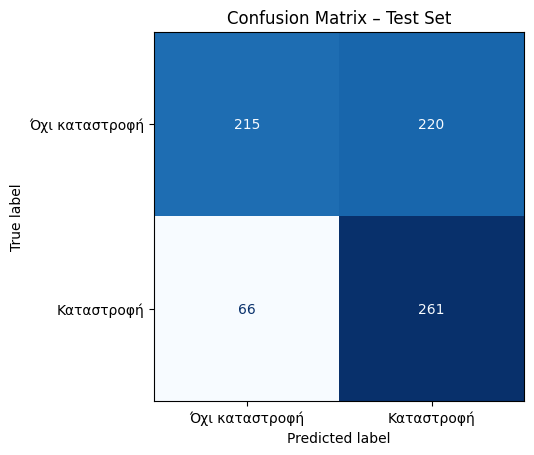

True Negatives: 215 | False Positives: 220
False Negatives: 66 | True Positives: 261


In [12]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Όχι καταστροφή', 'Καταστροφή'],
    cmap='Blues',
    colorbar=False,
)
plt.title('Confusion Matrix – Test Set')
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print('True Negatives:', tn, '| False Positives:', fp)
print('False Negatives:', fn, '| True Positives:', tp)

# Συμπέρασμα

Το test accuracy είναι 62,47% και το recall 79,82%. Το μοντέλο βρήκε 261 από τις 327 πραγματικές καταστροφές, αλλά έδωσε και 220 ψευδείς συναγερμούς. Για αυτό το recall είναι αρκετά καλό, ενώ το precision είναι χαμηλότερο. Ο Gaussian Naive Bayes είναι ένα απλό πρώτο μοντέλο, αλλά δεν θα ήταν αρκετά αξιόπιστος για πραγματική χρήση στο 112 χωρίς καλύτερο μοντέλο και έλεγχο από άνθρωπο.